[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_rigidb.ipynb)


# Rigid body

A rigid body is an ideal model in which $\left|\mathbf r_i-\mathbf r_j\right|$ is constant for every pair of material points. Its motion combines translation and rotation. Three noncollinear points determine the orientation of a body-fixed frame B relative to the laboratory frame L. The position of a material point is the sum of a reference position $\mathbf r_0$, such as the centre of mass, and its rotated body-frame position:

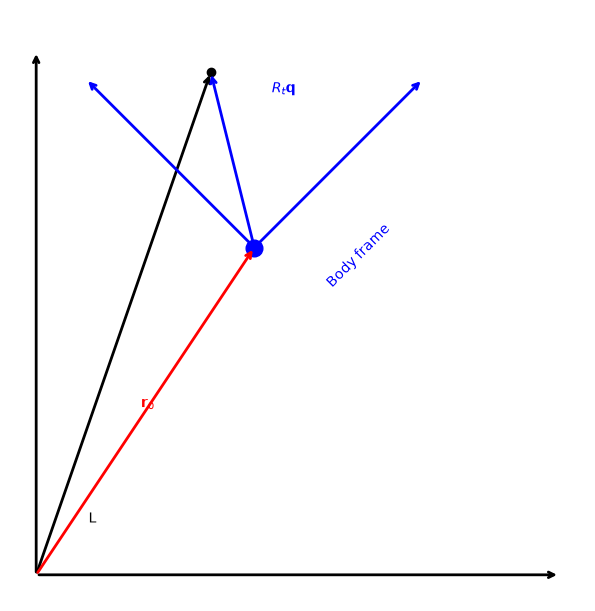

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


def animate_parameter(draw,minimum,maximum,value,step,label):
    draw(value)
    slider=widgets.FloatSlider(value=value,min=minimum,max=maximum,step=step,
                               description=label,continuous_update=False)
    play=widgets.Play(value=0,min=0,max=int(round((maximum-minimum)/step)),step=1,interval=120,repeat=False)
    def advance(change):
        slider.value=min(maximum,minimum+change['new']*step)
    play.observe(advance,names='value')
    view=widgets.interactive_output(lambda parameter: draw(parameter),{'parameter':slider})
    display(widgets.VBox([widgets.HBox([play,slider]),view]))
    return slider,play,view

from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy.integrate import solve_ivp
def ellipsoid(ax,radii,centre=(0,0,0),color='steelblue',alpha=.35):
    u,v=np.meshgrid(np.linspace(0,2*np.pi,65),np.linspace(0,np.pi,35))
    xyz=[centre[0]+radii[0]*np.sin(v)*np.cos(u),centre[1]+radii[1]*np.sin(v)*np.sin(u),centre[2]+radii[2]*np.cos(v)]
    ax.plot_surface(*xyz,color=color,alpha=alpha,linewidth=0)
def axes3d(fig):
    ax=fig.add_subplot(projection='3d'); ax.set(xlabel='x',ylabel='y',zlabel='z'); ax.set_box_aspect((1,1,1)); return ax
def Rz(q): return sp.Matrix([[sp.cos(q),-sp.sin(q),0],[sp.sin(q),sp.cos(q),0],[0,0,1]])
def Rx(q): return sp.Matrix([[1,0,0],[0,sp.cos(q),-sp.sin(q)],[0,sp.sin(q),sp.cos(q)]])
origin=np.array([.5,.75])/1.2; point=np.array([1/3,.96])
fig,ax=plt.subplots(figsize=(6,6),layout='constrained')
def arrow(start,end,color): ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->','color':color,'lw':2})
for end in ([1,0],[0,1],point): arrow([0,0],end,'black')
arrow([0,0],origin,'red'); arrow(origin,point,'blue')
for direction in ([1,1],[-1,1]): arrow(origin,origin+np.array(direction)/np.sqrt(2)/2.2,'blue')
ax.plot(*origin,'bo',ms=12); ax.plot(*point,'ko'); ax.text(.1,.1,'L'); ax.text(.2,.32,r'$\mathbf{r}_0$',color='red')
ax.text(.45,.92,r'$R_t\mathbf{q}$',color='blue'); ax.text(.55,.55,'Body frame',rotation=45,color='blue')
ax.set(aspect='equal',xlim=(-.05,1.05),ylim=(-.05,1.08)); ax.axis('off'); plt.show()

$$
\mathbf{r}\left(t\right) = {\mathbf{r}}_{0}\left(t\right)+R\left(t\right)\mathbf{q}\mathbf{ }\mathbf{\Rightarrow }\mathbf{ }\frac{d}{dt}\mathbf{r}\left(t\right)\mathbf{ }\mathbf{=}\mathbf{ }{\mathbf{v}}_{0}+\frac{dR}{dt}\mathbf{q}
$$

$R_t$ maps body-frame coordinates $\mathbf q$ to laboratory-frame displacement coordinates. The body’s orientation changes in the laboratory frame and remains fixed in its own frame.

## Rotation

Let’s consider rotation case only $\left({v}_{0}=0\right)$

$$
\mathbf{r}\left(t\right) = R\left(t\right)\mathbf{q}\mathbf{ }\mathbf{\Rightarrow }\mathbf{ }\frac{d\mathbf{r}}{dt}\mathbf{ }\mathbf{=}\frac{dR}{dt}\mathbf{q}\mathbf{=}\mathbf{ }\frac{dR}{dt}{R}^{-1}\mathbf{r}
$$

taking into account that for rotation ${R}_{t}^{-1}={R}_{t}^{T}$:

$$
0=\frac{d}{dt}\left(R {R}^{T}\right)=\frac{dR}{dt}{R}^{T}+R\frac{{dR}^{T}}{dt}=\frac{dR}{dt}{R}^{T}+{\left(\frac{dR}{dt}{R}^{T}\right)}^{T}
$$

which means that operator:

$$
\frac{dR}{dt}{R}^{T}: {R}^{3}\to {R}^{3}\Rightarrow \frac{dR}{dt}{R}^{T}=\left(\begin{matrix}0\\ {\omega }_{z}\\ -{\omega }_{y}\end{matrix}\begin{matrix}-{\omega }_{z}\\ 0\\ {\omega }_{x}\end{matrix}\begin{matrix}{\omega }_{y}\\ -{\omega }_{x}\\ 0\end{matrix}\right)
$$

is skew-symmetric. Every three-dimensional skew-symmetric operator represents a cross product:

$$
\left(\frac{dR}{dt}{R}^{T}\right)\mathbf{r}\mathbf{ }\mathbf{=}\mathbf{ }\mathbf{\omega \times r}
$$

In [2]:
wx,wy,wz,x,y,z=sp.symbols('omega_x omega_y omega_z x y z',real=True)
def skew(w): return sp.Matrix([[0,-w[2],w[1]],[w[2],0,-w[0]],[-w[1],w[0],0]])
w=sp.Matrix([wx,wy,wz]); r=sp.Matrix([x,y,z]); om=skew(w)
display(om*r==w.cross(r))

True

where ω is the angular velocity vector (in L-system)

In [3]:
wbody=sp.Matrix(sp.symbols('omega_1:4',real=True)); qbody=sp.Matrix(sp.symbols('x_1:4',real=True))
omg=skew(wbody); display(omg,omg*qbody==wbody.cross(qbody))

Matrix([
[       0, -omega_3,  omega_2],
[ omega_3,        0, -omega_1],
[-omega_2,  omega_1,        0]])

True

The angular velocity does not depend on the choice of reference point in the body; only $\mathbf v_0$ changes. Its direction determines the instantaneous rotation axis.

## Moment (tensor) of inertia

Let’s consider the kinetic energy of a rigid body

$$
{E}_{K}=\frac{1}{2}\sum {m}_{i}\frac{{\mathbf{v}}_{i}^{2}}{2}=\frac{1}{2}\sum {m}_{i}{\left({\mathbf{v}}_{0}+\mathbf{\omega }\mathbf{\times }{\mathbf{r}}^{\left(i\right)}\right)}^{2}=\frac{1}{2}\sum {m}_{i}\left({\mathbf{v}}_{0}^{2}+2{\mathbf{v}}_{0}\cdot \left(\omega \times {\mathbf{r}}^{\left(i\right)}\right)+{\left(\omega \times {\mathbf{r}}^{\left(i\right)}\right)}^{2}\right)=\frac{1}{2}\sum {m}_{i}{\mathbf{v}}_{0}^{2}+{\mathbf{v}}_{0}\cdot \left(\omega \times \sum {m}_{i}{\mathbf{r}}^{\left(i\right)}\right)+\frac{1}{2}\sum {m}_{i}{\omega }_{m}{\omega }_{n}\left({\mathbf{r}}_{\left(i\right)}^{2}{\delta }^{mn}-{x}_{\left(i\right)}^{m}{x}_{\left(i\right)}^{n}\right)
$$

As is clear from expression above if we choose ${r}_{0}$ to be at the center of inertia the kinetic energy splits into translational and rotational parts which are independent:

$$
{E}_{K}={E}_{ci}+\frac{1}{2}{I}^{mn}{\omega }_{m}{\omega }_{n}
$$

The quantity

$$
{I}^{mn}=\sum {m}_{i}\left({\mathbf{r}}_{\left(i\right)}^{2}{\delta }^{mn}-{x}_{\left(i\right)}^{m}{x}_{\left(i\right)}^{n}\right)=\int \rho \left(\mathbf{r}\right)\left({\mathbf{r}}^{2}{\delta }^{mn}-{x}^{m}{x}^{n}\right)dV\\ {I}^{xx}=\int \rho \left(\mathbf{r}\right)\left({y}^{2}+{z}^{2}\right)dV,{I}^{xy}=-\int \rho \left(\mathbf{r}\right)xydV, \text{etc}
$$

is the inertia tensor. It characterizes the body’s resistance to angular acceleration. In Cartesian coordinates, we need not distinguish upper and lower indices here.

For a unit vector $\mathbf n$ along a rotation axis, $I=\int\rho\left|\mathbf n\times\mathbf r\right|^2\,dV$: moving mass farther from the axis increases its moment of inertia. For a planar body in $z=0$, $I_{xx}+I_{yy}=I_{zz}$. The inertia tensor also follows from angular momentum about the centre of mass:

$$
\mathbf{L}=\sum {m}_{i}{\mathbf{r}}_{i}\times {\mathbf{v}}_{i}=\sum {m}_{i}{\mathbf{r}}^{\left(i\right)}\times \left({\mathbf{v}}_{0}+\mathbf{\omega }\mathbf{\times }{\mathbf{r}}^{\left(i\right)}\right)=\sum {m}_{i}\left(\mathbf{\omega }\mathbf{ }{\mathbf{r}}^{{\left(i\right)}^{2}}-\mathbf{\omega }\mathbf{\cdot }{\mathbf{r}}^{\left(i\right)}{\mathbf{r}}^{\left(i\right)}\right)=I.\mathbf{\omega }
$$

As any symmetrical tensor it can be diagonalized by orthogonal transformation

$$
I = \left(\begin{matrix}{I}_{1}\\ 0\\ 0\end{matrix}\begin{matrix}0\\ {I}_{2}\\ 0\end{matrix}\begin{matrix}0\\ 0\\ {I}_{3}\end{matrix}\right), {I}_{1}+{I}_{2}+{I}_{3}=2\int \rho \left(\mathbf{r}\right){\mathbf{r}}^{2}dV, \\ {I}_{1}+{I}_{2}\ge {I}_{3},{I}_{3}+{I}_{1}\ge {I}_{2},{I}_{3}+{I}_{2}\ge {I}_{1}
$$

which means that rigid bodies form 3-parameter set (analogously the set of material points wrt translational motion is 1-parameter set with mass as scalar parameter). The corresponding axes are called principal ones. Commonly they are chosen as the axes of the body-fixed coordinate system which rotates wrt L-frame.  The equation

$$
{I}_{1}{\Omega }_{1}^{2}+{I}_{2}{\Omega }_{2}^{2}+{I}_{3}{\Omega }_{3}^{2}=1
$$

determines the ellipsoid of inertia. Here Ω is the vector of angular velocity in body-fixed frame. 

$$
\left({R}^{T}\frac{dR}{dt}\right)\mathbf{q}\mathbf{ }\mathbf{=}\mathbf{ }\mathbf{\Omega \times q}
$$

The body-frame angular velocity Ω determines the instantaneous rotation axis in that frame.

The principal moments classify a spherical top ($I_1=I_2=I_3$), an oblate symmetric top ($I_1=I_2<I_3$), or a prolate symmetric top ($I_1=I_2>I_3$). Rotational symmetry of order at least three makes the inertia ellipsoid axially symmetric. For an equilateral triangle, planarity gives $I_1+I_2=I_3$, and symmetry gives $I_1=I_2$.

| Principal moments | Body |
|---|---|
| $I_1=I_2=I_3$ | Spherical top |
| $I_1=I_2<I_3$ | Oblate symmetric top |
| $I_1=I_2>I_3$ | Prolate symmetric top |
| $I_1+I_2=I_3$ | Planar body |

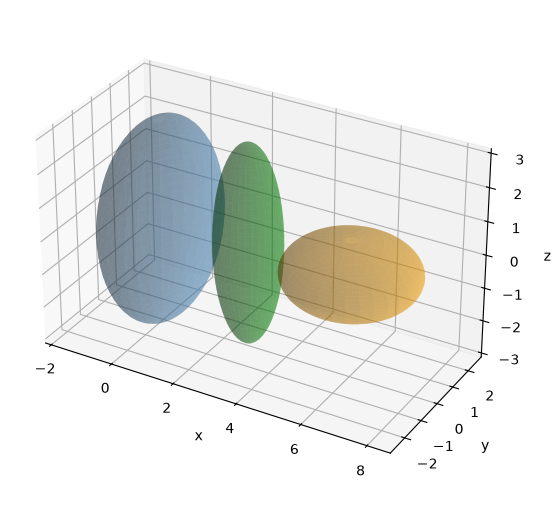

In [4]:
fig=plt.figure(figsize=(9,5),layout='constrained'); ax=axes3d(fig)
for radii,centre,color in [((1.5,2.5,3),(0,0,0),'steelblue'),((2,2,1),(6,0,0),'orange'),((1,1,3),(2.8,0,0),'green')]:
    ellipsoid(ax,radii,centre,color)
ax.set_box_aspect((10,5,6)); plt.show()

## Equilateral triangle

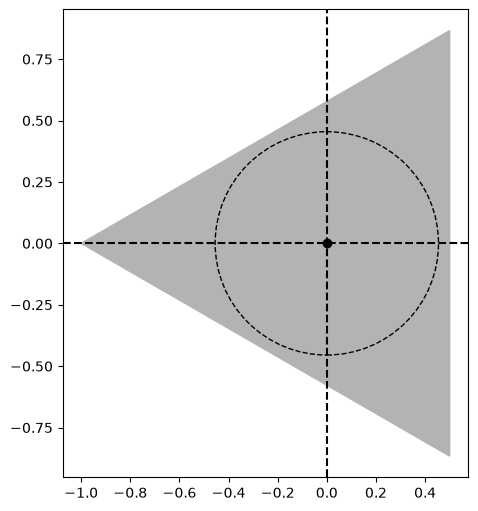

In [5]:
angles=np.arange(3)*2*np.pi/3+np.pi/3
triangle=np.array([np.cos(angles),np.sin(angles)]).T
fig,ax=plt.subplots(figsize=(5,5),layout='constrained'); ax.fill(*triangle.T,color='.7')
ax.plot(0,0,'ko'); ax.axhline(0,ls='--',color='black'); ax.axvline(0,ls='--',color='black')
ax.add_patch(plt.Circle((0,0),1/2.2,fill=False,ls='--')); ax.set(aspect='equal'); plt.show()

$$
{I}_{1}=2\rho {\int }_{0}^{\frac{x}{\sqrt{3}}}{\int }_{0}^{\frac{\sqrt{3}}{2}}{y}^{2}dxdy=\frac{\rho }{32} \frac{{a}^{4}}{\sqrt{3}}={I}_{2}=m \frac{{a}^{2}}{24} \Rightarrow {I}_{3}={I}_{1}+{I}_{2}=m \frac{{a}^{2}}{12}
$$

In [6]:
a=sp.symbols('a',positive=True)
i12=2*sp.integrate(sp.integrate(y**2,(y,0,x/sp.sqrt(3))),(x,0,a*sp.sqrt(3)/2))
area=a**2*sp.sqrt(3)/4
display(i12,sp.simplify(i12/area))

sqrt(3)*a**4/96

a**2/24

Alternatively, calculate $I_3$ by integrating over a family of similar triangles:

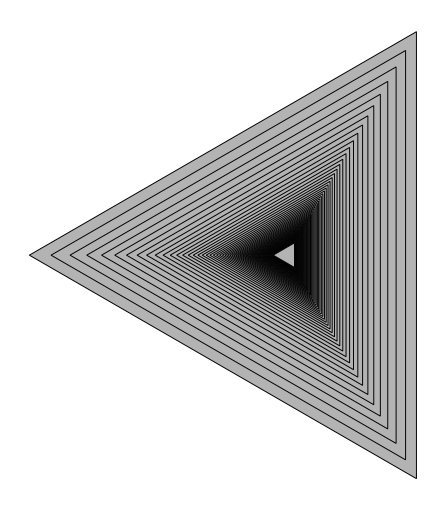

In [7]:
fig,ax=plt.subplots(figsize=(5,5),layout='constrained')
for scale in 1/np.arange(1,5.001,.05)**1.8:
    ax.fill(*(scale*triangle).T,facecolor='.7',edgecolor='black',lw=.7)
ax.set(aspect='equal'); ax.axis('off'); plt.show()

$$
{I}_{3}=3\rho \int dI={\int }_{0}^{\frac{a}{2\sqrt{3}}}\left(\frac{{l}^{2}}{12}+{x}^{2}\right)l dx, x=\frac{l}{2\sqrt{3}}
$$

In [8]:
i3=3*sp.integrate((y**2/12+(y/(2*sp.sqrt(3)))**2)*y/(2*sp.sqrt(3)),(y,0,a))/area
display(sp.simplify(i3))

a**2/12

Clearly, we get the same result as above.

In [9]:
def simplex_inertia(vertices):
    # Uniform filled simplex: covariance = sum(v-centre)(v-centre)^T / [n(n+1)].
    n=len(vertices); centre=sum(vertices,sp.zeros(len(vertices[0]),1))/n
    covariance=sum(((v-centre)*(v-centre).T for v in vertices),sp.zeros(len(centre)))/(n*(n+1))
    return sp.simplify(sp.trace(covariance)*sp.eye(len(centre))-covariance)
triangle_vertices=[sp.Matrix([sp.cos(q),sp.sin(q)])/sp.sqrt(3) for q in [0,2*sp.pi/3,4*sp.pi/3]]
display(simplex_inertia(triangle_vertices))

Matrix([
[1/24,    0],
[   0, 1/24]])

## Example: Cube

A homogeneous cube is a spherical top:

$$
{I}_{3}=\rho {\int }_{-a/2}^{a/2}{\int }_{-a/2}^{a/2}{\int }_{-a/2}^{a/2}\left({x}^{2}+{y}^{2}\right)dxdydz=\frac{\rho }{3} \frac{{a}^{5}}{2}={I}_{1}={I}_{2}=\frac{M {a}^{2}}{6}
$$

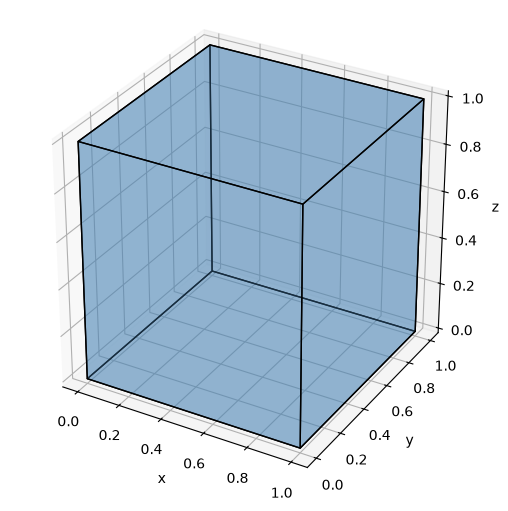

In [10]:
from itertools import product,combinations
vertices=np.array(list(product([0,1],repeat=3)))
fig=plt.figure(figsize=(5,5),layout='constrained'); ax=axes3d(fig)
faces=[]
for dim in range(3):
    for side in (0,1):
        face=vertices[vertices[:,dim]==side][[0,1,3,2]]; faces.append(face)
ax.add_collection3d(Poly3DCollection(faces,facecolor='steelblue',edgecolor='black',alpha=.35)); ax.auto_scale_xyz([0,1],[0,1],[0,1]); plt.show()

which can be calculated also as

$$
3I=2\rho {\int }_{-a/2}^{a/2}{\int }_{-a/2}^{a/2}{\int }_{-a/2}^{a/2}\left({x}^{2}+{y}^{2}+{z}^{2}\right)dxdydz=\rho  \frac{{a}^{5}}{2}\Rightarrow I=\frac{M {a}^{2}}{6}
$$

In [11]:
r=sp.Matrix([x,y,z]); inertia_density=(r.dot(r))*sp.eye(3)-r*r.T
cube_inertia=inertia_density.applyfunc(lambda f:sp.integrate(f,(x,-sp.Rational(1,2),sp.Rational(1,2)),(y,-sp.Rational(1,2),sp.Rational(1,2)),(z,-sp.Rational(1,2),sp.Rational(1,2))))
display(cube_inertia)

Matrix([
[1/6,   0,   0],
[  0, 1/6,   0],
[  0,   0, 1/6]])

In [12]:
q=sp.symbols('q',real=True); radius=sp.symbols('r',nonnegative=True)
# By spherical symmetry all three diagonal moments are equal.
sphere_moment=sp.integrate(sp.sin(q)**3,(q,0,sp.pi))/2
ball_moment=sphere_moment*sp.integrate(radius**4,(radius,0,1))/sp.integrate(radius**2,(radius,0,1))
display(sphere_moment*sp.eye(3),ball_moment*sp.eye(3))

Matrix([
[2/3,   0,   0],
[  0, 2/3,   0],
[  0,   0, 2/3]])

Matrix([
[2/5,   0,   0],
[  0, 2/5,   0],
[  0,   0, 2/5]])

## Example: Regular tetrahedron (solid)

Divide the solid into equilateral triangular layers and use the preceding planar result.

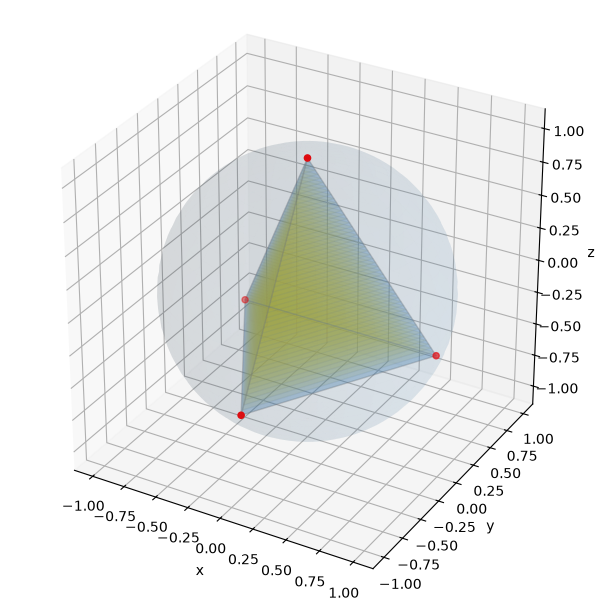

In [13]:
p0=sp.Matrix([0,0,1]); p1=Rx(2*sp.pi/3)*p0; p2=Rz(2*sp.pi/3)*p1; p3=Rz(2*sp.pi/3)*p2
p=np.array([list(v) for v in [p0,p1,p2,p3]],dtype=float)
fig=plt.figure(figsize=(6,6),layout='constrained'); ax=axes3d(fig)
faces=[p[list(face)] for face in combinations(range(4),3)]
ax.add_collection3d(Poly3DCollection(faces,alpha=.2,facecolor='steelblue',edgecolor='gray'))
layers=[p[0]+(p[1:]-p[0])*fraction/50 for fraction in range(1,50)]
ax.add_collection3d(Poly3DCollection(layers,alpha=.12,edgecolor='gray',facecolor='gold'))
ellipsoid(ax,(1,1,1),alpha=.08); ax.scatter(*p.T,color='red'); plt.show()
# These original illustration vertices are not a regular tetrahedron.

$$
{I}_{3}=\int dI=\int \frac{{l}^{2}}{12}dm={\int }_{0}^{a\sqrt{\frac{2}{3}}}\sqrt{3}\frac{{l}^{2}}{4}\frac{{l}^{2}}{12} dh, \\ h=l\sqrt{\frac{2}{3}},m=\rho  {a}^{3}\frac{\sqrt{2}}{12}
$$

In [14]:
display(sp.simplify(sp.integrate(x**2/12*x**2*sp.sqrt(3)/4*sp.sqrt(2)/sp.sqrt(3),(x,0,a))/(sp.sqrt(2)*a**3/12)))

a**2/20

$$
{I}_{1}={I}_{2}={I}_{3}=m \frac{{a}^{2}}{20}
$$

In [15]:
tetra_vertices=[sp.Matrix(v)/(2*sp.sqrt(2)) for v in [(1,1,1),(1,-1,-1),(-1,1,-1),(-1,-1,1)]]
tetra_inertia=simplex_inertia(tetra_vertices)
display(tetra_inertia)

Matrix([
[1/20,    0,    0],
[   0, 1/20,    0],
[   0,    0, 1/20]])

In [16]:
tetra_volume=abs(sp.Matrix.hstack(*(v-tetra_vertices[0] for v in tetra_vertices[1:])).det())/6
display(tetra_volume)

sqrt(2)/12

## Kinematics of rotation. Euler’s angles

Euler’s angles describe the orientation of a rigid body relative to a laboratory frame XYZ. The axes x1, x2, x3 are attached to the body.



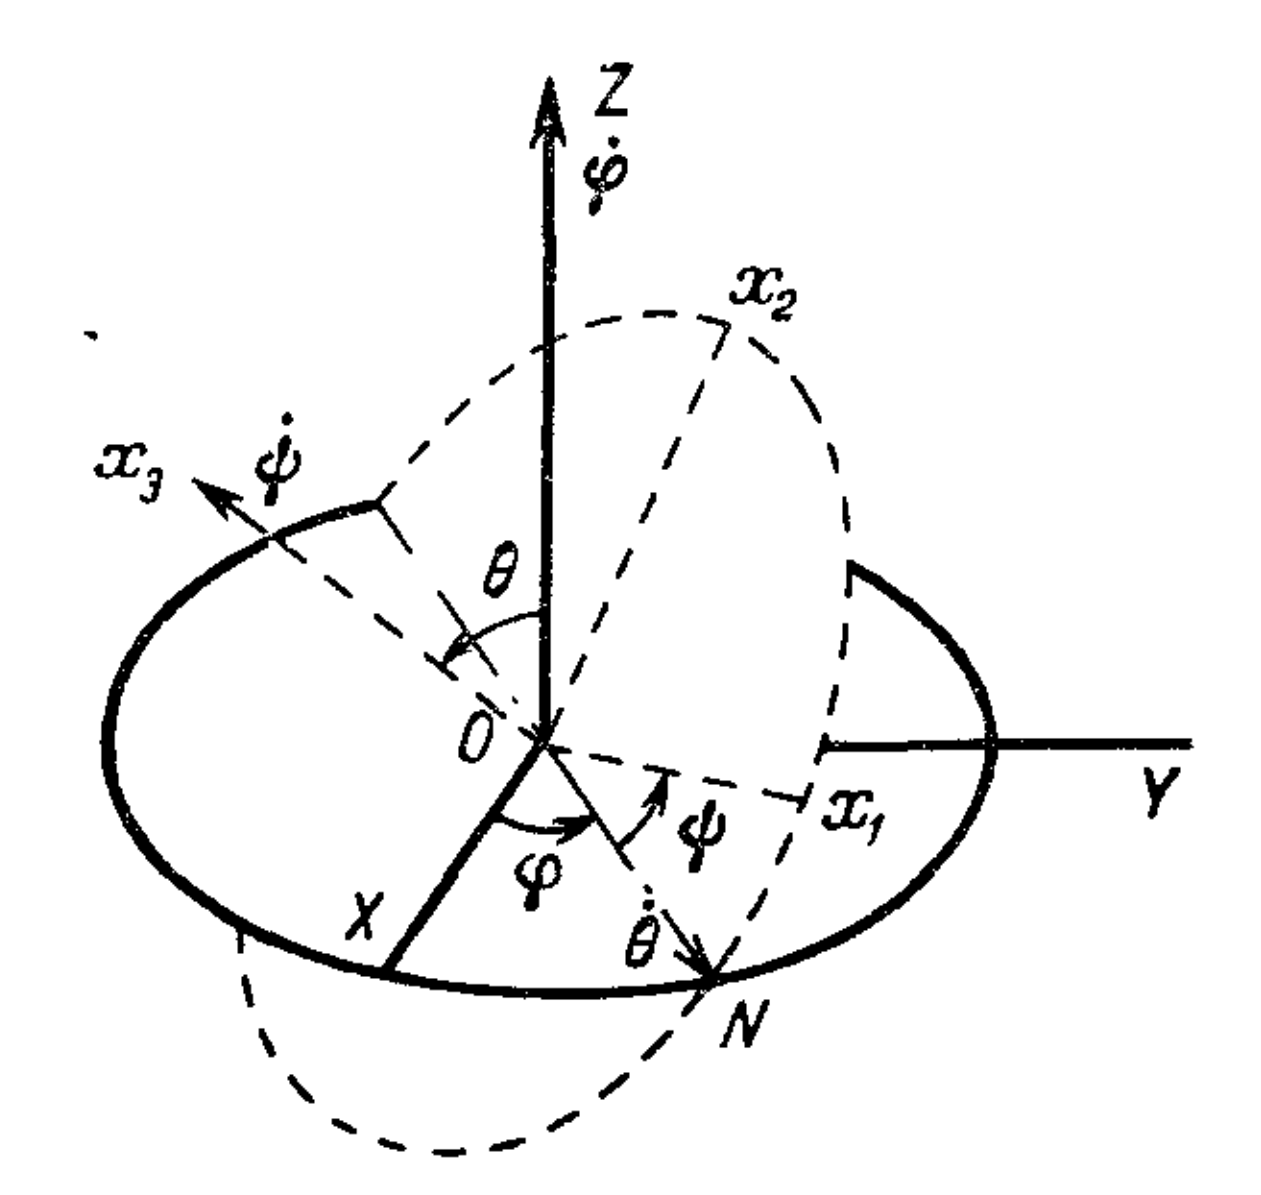


Fig. Euler’s angles. N  is the node axis as the intersection of XY and x1x2 planes
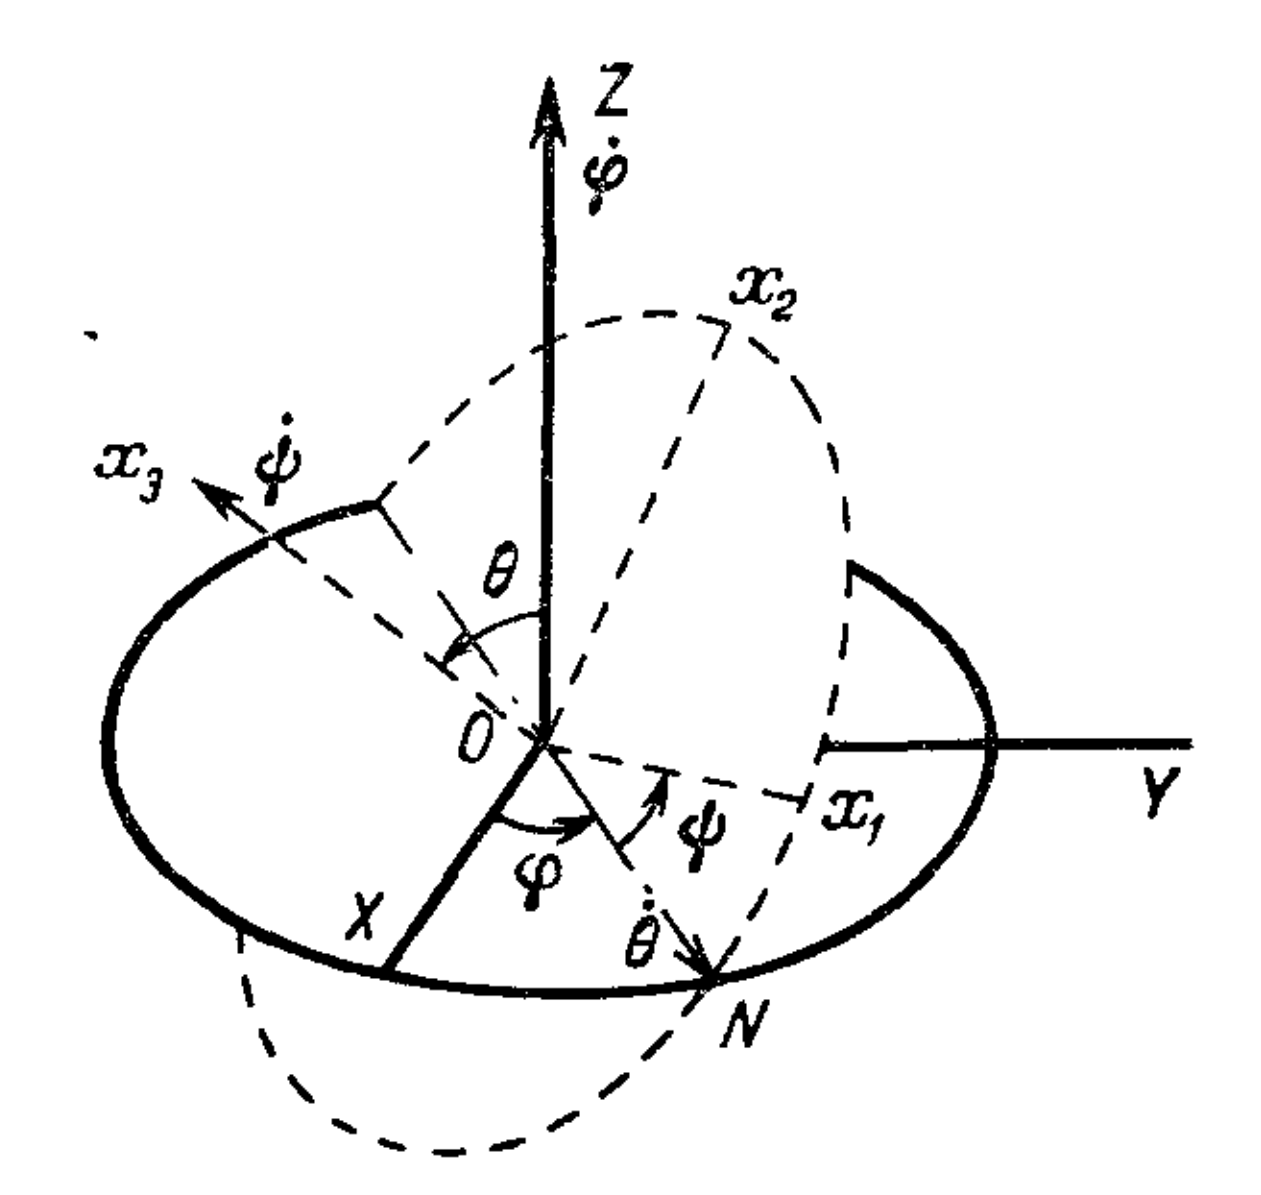

The frames are related by successive rotations: first around Z by $\varphi$, then around the node axis by $\theta$, and finally around x3 by $\psi$. This is the intrinsic ZXZ convention.

$$
{\mathbf{e}}_{k}=O\left(\varphi ,\theta ,\psi \right){\mathbf{i}}_{k}, k=1,2,3\\ O\left(\varphi ,\theta ,\psi \right)={O}_{3}\left(\psi \right)\circ  {O}_{1}\left(\theta \right)\circ  {O}_{3}\left(\varphi \right)\\ {\mathbf{i}}_{k}={O}^{T}\left(\varphi ,\theta ,\psi \right){e}_{k}={O}_{3}^{T}\left(\varphi \right)\circ  {O}_{1}^{T}\left(\theta \right)\circ  {O}_{3}^{T}\left(\psi \right){e}_{k}
$$

where O is the orthogonal matrix of corresponding rotations:

In [17]:
phi,theta,psi=sp.symbols('varphi theta psi',real=True)
display(Rz(phi),Rx(theta),Rz(psi))

Matrix([
[cos(varphi), -sin(varphi), 0],
[sin(varphi),  cos(varphi), 0],
[          0,            0, 1]])

Matrix([
[1,          0,           0],
[0, cos(theta), -sin(theta)],
[0, sin(theta),  cos(theta)]])

Matrix([
[cos(psi), -sin(psi), 0],
[sin(psi),  cos(psi), 0],
[       0,         0, 1]])

So the coordinates are related

$$
\left(\begin{matrix}{x}_{1}\\ {x}_{2}\\ {x}_{3}\end{matrix}\right)=\left(\begin{matrix}\cos{\alpha } & -\sin{\alpha } & 0\\ \sin{\alpha } & \cos{\alpha } & 0\\ 0 & 0 & 1\end{matrix}\right)\left(\begin{matrix}{x}_{1}^{'}\\ {x}_{2}^{'}\\ {x}_{3}^{'}\end{matrix}\right)
$$

Then the rotation matrix R which rotates the body is 

In [18]:
eulermtrx=Rz(phi)*Rx(theta)*Rz(psi)
display(eulermtrx)
display(sp.trigsimp(eulermtrx.T*eulermtrx)==sp.eye(3))

Matrix([
[-sin(psi)*sin(varphi)*cos(theta) + cos(psi)*cos(varphi), -sin(psi)*cos(varphi) - sin(varphi)*cos(psi)*cos(theta),  sin(theta)*sin(varphi)],
[ sin(psi)*cos(theta)*cos(varphi) + sin(varphi)*cos(psi), -sin(psi)*sin(varphi) + cos(psi)*cos(theta)*cos(varphi), -sin(theta)*cos(varphi)],
[                                    sin(psi)*sin(theta),                                     sin(theta)*cos(psi),              cos(theta)]])

True

In [19]:
# Intrinsic ZXZ Euler rotations, matching the source's {3,1,3} convention.
display(Rz(phi)*Rx(theta)*Rz(psi),eulermtrx)

Matrix([
[-sin(psi)*sin(varphi)*cos(theta) + cos(psi)*cos(varphi), -sin(psi)*cos(varphi) - sin(varphi)*cos(psi)*cos(theta),  sin(theta)*sin(varphi)],
[ sin(psi)*cos(theta)*cos(varphi) + sin(varphi)*cos(psi), -sin(psi)*sin(varphi) + cos(psi)*cos(theta)*cos(varphi), -sin(theta)*cos(varphi)],
[                                    sin(psi)*sin(theta),                                     sin(theta)*cos(psi),              cos(theta)]])

Matrix([
[-sin(psi)*sin(varphi)*cos(theta) + cos(psi)*cos(varphi), -sin(psi)*cos(varphi) - sin(varphi)*cos(psi)*cos(theta),  sin(theta)*sin(varphi)],
[ sin(psi)*cos(theta)*cos(varphi) + sin(varphi)*cos(psi), -sin(psi)*sin(varphi) + cos(psi)*cos(theta)*cos(varphi), -sin(theta)*cos(varphi)],
[                                    sin(psi)*sin(theta),                                     sin(theta)*cos(psi),              cos(theta)]])

In [20]:
# The original cell contains only a commented-out alternative rotation demonstration.
# Its full source is retained in this cell’s metadata.

The angular velocity vector ω can be constructed as a sum of these rotation components

$$
\mathbf{\omega } = \dot{\varphi } \mathbf{k}\mathbf{+}\dot{\theta } {\mathbf{e}}_{N}+\dot{\psi } {\mathbf{e}}_{3}
$$

In [21]:
phi1,theta1,psi1=sp.symbols('varphi_dot theta_dot psi_dot',real=True)
ez=sp.Matrix([0,0,1]); ex=sp.Matrix([1,0,0])
om0=phi1*ez+theta1*Rz(phi)*ex+psi1*eulermtrx*ez
display(om0,sp.trigsimp(om0.dot(om0)),om0)

Matrix([
[ psi_dot*sin(theta)*sin(varphi) + theta_dot*cos(varphi)],
[-psi_dot*sin(theta)*cos(varphi) + theta_dot*sin(varphi)],
[                        psi_dot*cos(theta) + varphi_dot]])

psi_dot**2 + 2*psi_dot*varphi_dot*cos(theta) + theta_dot**2 + varphi_dot**2

Matrix([
[ psi_dot*sin(theta)*sin(varphi) + theta_dot*cos(varphi)],
[-psi_dot*sin(theta)*cos(varphi) + theta_dot*sin(varphi)],
[                        psi_dot*cos(theta) + varphi_dot]])

Comparison with the definition above:

In [22]:
eulermtrx1=sum((sp.diff(eulermtrx,q)*rate for q,rate in zip((phi,theta,psi),(phi1,theta1,psi1))),sp.zeros(3))
rotom=sp.trigsimp(eulermtrx1*eulermtrx.T)
def axial(matrix): return sp.Matrix([matrix[2,1],matrix[0,2],matrix[1,0]])
om1=axial(rotom); display(rotom,om1,sp.trigsimp(om1.dot(om1)),om1)

Matrix([
[                                                     0,                       -psi_dot*cos(theta) - varphi_dot, -psi_dot*sin(theta)*cos(varphi) + theta_dot*sin(varphi)],
[                       psi_dot*cos(theta) + varphi_dot,                                                      0, -psi_dot*sin(theta)*sin(varphi) - theta_dot*cos(varphi)],
[psi_dot*sin(theta)*cos(varphi) - theta_dot*sin(varphi), psi_dot*sin(theta)*sin(varphi) + theta_dot*cos(varphi),                                                       0]])

Matrix([
[ psi_dot*sin(theta)*sin(varphi) + theta_dot*cos(varphi)],
[-psi_dot*sin(theta)*cos(varphi) + theta_dot*sin(varphi)],
[                        psi_dot*cos(theta) + varphi_dot]])

psi_dot**2 + 2*psi_dot*varphi_dot*cos(theta) + theta_dot**2 + varphi_dot**2

Matrix([
[ psi_dot*sin(theta)*sin(varphi) + theta_dot*cos(varphi)],
[-psi_dot*sin(theta)*cos(varphi) + theta_dot*sin(varphi)],
[                        psi_dot*cos(theta) + varphi_dot]])

In [23]:
display(sp.trigsimp(om1-om0)==sp.zeros(3,1))

True

Vector Ω in body-reference system according to definition is:

$$
\frac{d\mathbf{r}}{dt}=\frac{dR}{dt}\mathbf{q}\mathbf{\Rightarrow }{R}^{T}\frac{d\mathbf{r}}{dt}={R}^{T}\frac{dR}{dt}\mathbf{q}\mathbf{=}\mathbf{\Omega \times q\Rightarrow \Omega }\mathbf{ }\mathbf{=}\mathbf{ }{R}^{T}\mathbf{ }\mathbf{\omega }
$$

$$
\mathbf{\Omega }\mathbf{ }\mathbf{=}\left(\dot{\varphi }\sin{\psi}  \sin{\theta} +\dot{\theta }\cos{\psi} \right){\mathbf{e}}_{1}+\left(\dot{\varphi }\cos{\psi}  \sin{\theta} -\dot{\theta }\sin{\psi} \right){\mathbf{e}}_{2}+\mathbf{ }\left(\dot{\varphi } \cos{\theta} +\dot{\psi }\right){\mathbf{e}}_{3}
$$

In [24]:
rotOm=sp.trigsimp(eulermtrx.T*eulermtrx1); Om1=axial(rotOm)
display(rotOm,Om1,sp.trigsimp(Om1.dot(Om1)),Om1)

Matrix([
[                                                  0,                    -psi_dot - varphi_dot*cos(theta), -theta_dot*sin(psi) + varphi_dot*sin(theta)*cos(psi)],
[                    psi_dot + varphi_dot*cos(theta),                                                   0, -theta_dot*cos(psi) - varphi_dot*sin(psi)*sin(theta)],
[theta_dot*sin(psi) - varphi_dot*sin(theta)*cos(psi), theta_dot*cos(psi) + varphi_dot*sin(psi)*sin(theta),                                                    0]])

Matrix([
[ theta_dot*cos(psi) + varphi_dot*sin(psi)*sin(theta)],
[-theta_dot*sin(psi) + varphi_dot*sin(theta)*cos(psi)],
[                     psi_dot + varphi_dot*cos(theta)]])

psi_dot**2 + 2*psi_dot*varphi_dot*cos(theta) + theta_dot**2 + varphi_dot**2

Matrix([
[ theta_dot*cos(psi) + varphi_dot*sin(psi)*sin(theta)],
[-theta_dot*sin(psi) + varphi_dot*sin(theta)*cos(psi)],
[                     psi_dot + varphi_dot*cos(theta)]])

In [25]:
display(sp.Matrix([sp.trigsimp(om0.dot(eulermtrx[:,j])) for j in range(3)]))

Matrix([
[ theta_dot*cos(psi) + varphi_dot*sin(psi)*sin(theta)],
[-theta_dot*sin(psi) + varphi_dot*sin(theta)*cos(psi)],
[                     psi_dot + varphi_dot*cos(theta)]])

In [26]:
display(sp.trigsimp(eulermtrx.T*om0))

Matrix([
[ theta_dot*cos(psi) + varphi_dot*sin(psi)*sin(theta)],
[-theta_dot*sin(psi) + varphi_dot*sin(theta)*cos(psi)],
[                     psi_dot + varphi_dot*cos(theta)]])

Rotational velocities ω and Ω as operators (ω×...) are related as follows

$$
\mathbf{\hat{\mathbf{\Omega }}}\mathbf{ }\mathbf{=}\mathbf{ }{R}^{T}\mathbf{ }\mathbf{\hat{\mathbf{\omega }}}R
$$

In [27]:
display(sp.trigsimp(eulermtrx.T*rotom*eulermtrx-rotOm)==sp.zeros(3))

True

The angles $\varphi$, $\theta$, and $\psi$ describe precession, nutation, and proper rotation, respectively.

$$
\begin{matrix}\text{Euler angle} & \text{Name}\\ \varphi  & \text{precession}\\ \theta  & \text{nutation}\\ \psi  & \text{proper rotation}\end{matrix}
$$

## Free rotation

The Lagrange function of a free rotating (around center of inertia) body is 

$$
\text{Lagrange}=\frac{1}{2}\sum {I}_{ij}{\Omega }_{i}{\Omega }_{j}
$$

The EoM are

$$
\frac{d}{dt}\left(\frac{\partial Lgr}{\partial  {\Omega }_{i} }\right)-\frac{\partial Lgr}{\partial  {q}_{i} }=\frac{d}{dt}\left(\sum {I}_{ij}{\Omega }_{j}\right)=0
$$

so it is natural consequence of inertia that the angular  momentum is conserved:

$$
\frac{d \mathbf{L}}{dt}=0
$$

Conservation of angular momentum does not imply constant angular velocity. Steady free rotation occurs along a principal axis, reflecting the tensor character of rotational inertia.

$$
\frac{d \mathbf{p}}{dt}=0\Rightarrow \frac{d\mathbf{v}}{dt}=0
$$

In [28]:
source_moments=np.array([1.,2.,1.5])

In the body frame, angular momentum is $\mathbf M=R^{-1}\mathbf L$, so its components change according to

$$
0=\frac{d \mathbf{L}}{dt}=\frac{dR}{dt}\mathbf{M}+R \frac{d\mathbf{M}}{dt}=R\left({R}^{-1}\frac{dR}{dt}\mathbf{M}+ \frac{d\mathbf{M}}{dt}\right)=R\left(\mathbf{\Omega }\times \mathbf{M}+ \frac{d \mathbf{M}}{dt}\right)\Rightarrow  \frac{d \mathbf{M}}{dt}+\mathbf{\Omega }\times \mathbf{M}=0
$$

Therefore in fixed-body system vector M moves around Ω. In terms of components of Ω

$$
{I}_{1}\frac{d {\mathbf{\Omega }}_{1}}{dt}=\left({I}_{2}-{I}_{3}\right){\Omega }_{2}{\Omega }_{3}\\ {I}_{2}\frac{d {\mathbf{\Omega }}_{2}}{dt}=\left({I}_{3}-{I}_{1}\right){\Omega }_{3}{\Omega }_{1}\\ {I}_{3}\frac{d {\mathbf{\Omega }}_{3}}{dt}=\left({I}_{1}-{I}_{2}\right){\Omega }_{1}{\Omega }_{2}
$$

The conserved kinetic energy and angular momentum magnitude constrain the tip of the body-frame angular momentum vector to the intersection of an ellipsoid and a sphere.

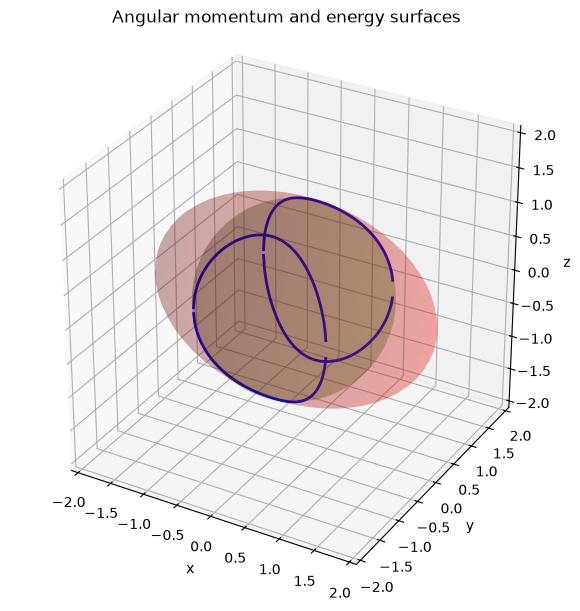

interactive(children=(FloatSlider(value=1.7, description='level', max=3.7, min=0.9, step=0.02), Output()), _do…

In [29]:
def show_invariants(level=1.7):
    fig=plt.figure(figsize=(6,6),layout='constrained'); ax=axes3d(fig)
    ellipsoid(ax,(2,1,np.sqrt(2)),color='red',alpha=.18)
    ellipsoid(ax,(np.sqrt(level),)*3,color='green',alpha=.16)
    angle=np.linspace(0,2*np.pi,3000); A=np.cos(angle)**2/4+np.sin(angle)**2
    with np.errstate(divide='ignore',invalid='ignore'):
        z2=(1-level*A)/(.5-A)
    valid=(z2>=0)&(z2<=level)
    zcoord=np.sqrt(np.where(valid,z2,np.nan)); rxy=np.sqrt(np.where(valid,level-z2,np.nan))
    for sign in (-1,1): ax.plot(rxy*np.cos(angle),rxy*np.sin(angle),sign*zcoord,color='blue',lw=2)
    ax.set(xlim=(-2.1,2.1),ylim=(-2.1,2.1),zlim=(-2.1,2.1),title='Angular momentum and energy surfaces'); plt.show()
show_invariants()
invariant_controls=widgets.interactive(show_invariants,level=widgets.FloatSlider(min=.9,max=3.7,step=.02,value=1.7))
display(invariant_controls)

Rotations around the axes with largest and smallest principal moments are stable; rotation around the intermediate axis is unstable (the tennis-racket theorem, also called the Dzhanibekov effect).

Let’s visualize the motion of vector Ω for free rotation in body-fixed frame

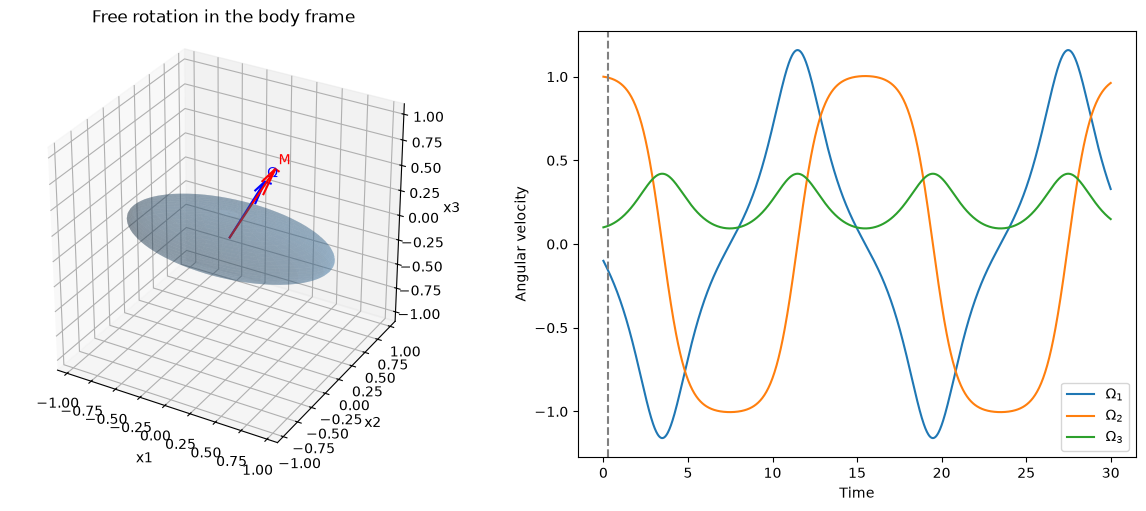

In [30]:
moments=np.array([1.,2.,4.]); tmax=30.
def euler_rhs(t,w): return -np.cross(w,moments*w)/moments
solution=solve_ivp(euler_rhs,(0,tmax),[-.1,1.,.1],method='DOP853',rtol=1e-11,atol=1e-13,dense_output=True)
assert solution.success
def omega(t): return solution.sol(t)
def momentum(t): return moments[:,None]*omega(t) if np.ndim(t) else moments*omega(t)
times=np.linspace(0,tmax,1000); all_omega=omega(times)
def show_rotation(time):
    fig=plt.figure(figsize=(12,5),layout='constrained'); ax=fig.add_subplot(121,projection='3d'); ax2=fig.add_subplot(122)
    ellipsoid(ax,1/moments,alpha=.3)
    trace=np.linspace(0,time,max(2,int(600*time/tmax)))
    for vectors,scale,color,label in [(omega,1/1.1,'blue',r'$\Omega$'),(momentum,1/1.01,'red','M')]:
        track=vectors(trace); track=scale*track/np.linalg.norm(track,axis=0)
        ax.plot(*track,color=color); endpoint=track[:,-1]; ax.quiver(0,0,0,*endpoint,color=color)
        ax.text(*(1.07*endpoint),label,color=color)
    ax.set(xlim=(-1.1,1.1),ylim=(-1.1,1.1),zlim=(-1.1,1.1),xlabel='x1',ylabel='x2',zlabel='x3',title='Free rotation in the body frame'); ax.set_box_aspect((1,1,1))
    for j,values in enumerate(all_omega): ax2.plot(times,values,label=rf'$\Omega_{j+1}$')
    ax2.axvline(time,color='gray',ls='--'); ax2.set(xlabel='Time',ylabel='Angular velocity'); ax2.legend(); plt.show()
rotation_controls=animate_parameter(show_rotation,.3,tmax,.3,.15,'Time')

Checking the conservation of the angular momentum

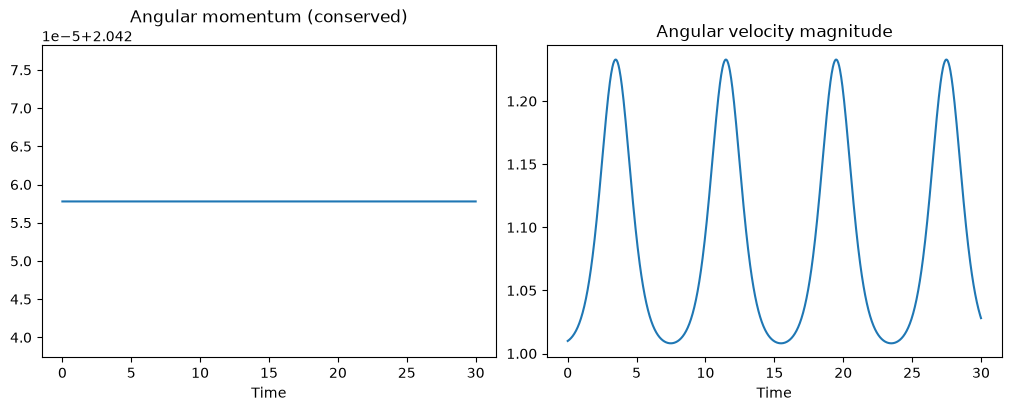

In [31]:
mom_norm=np.linalg.norm(momentum(times),axis=0); omega_norm=np.linalg.norm(all_omega,axis=0)
energy=np.sum(moments[:,None]*all_omega**2,axis=0)/2
assert np.max(np.abs(mom_norm/mom_norm[0]-1))<1e-8
assert np.max(np.abs(energy/energy[0]-1))<1e-8
fig,axes=plt.subplots(1,2,figsize=(10,4),layout='constrained')
axes[0].plot(times,mom_norm); axes[0].set(title='Angular momentum (conserved)',ylim=(mom_norm[-1]/1.00001,mom_norm[-1]*1.00001),xlabel='Time')
axes[1].plot(times,omega_norm); axes[1].set(title='Angular velocity magnitude',xlabel='Time'); plt.show()

If there is external torque T then (N is the torque vector wrt fixed-body system):

$$
\frac{d \mathbf{L}}{dt}=\mathbf{T}\mathbf{\Rightarrow }\frac{d \mathbf{M}}{dt}+\mathbf{\Omega }\times \mathbf{M}=\mathbf{N}\mathbf{,}\mathbf{ }\mathbf{T}\mathbf{=}R\mathbf{ }\mathbf{N}
$$

This is Euler’s equation of rigid body rotation

## Poinsot construction

Poinsot’s construction describes free rotation in the laboratory frame: angular momentum $\mathbf L$ is fixed, while the inertia ellipsoid moves with the body and rolls without slipping on a plane perpendicular to $\mathbf L$.

$$
\text{const}={E}_{\text{kin}}=\frac{1}{2}I.\mathbf{\omega }.\mathbf{\omega }=\frac{1}{2}\mathbf{\omega  \cdot L} \Rightarrow  \mathbf{L}= {\nabla }_{\mathbf{\omega }}{E}_{\text{kin}}
$$



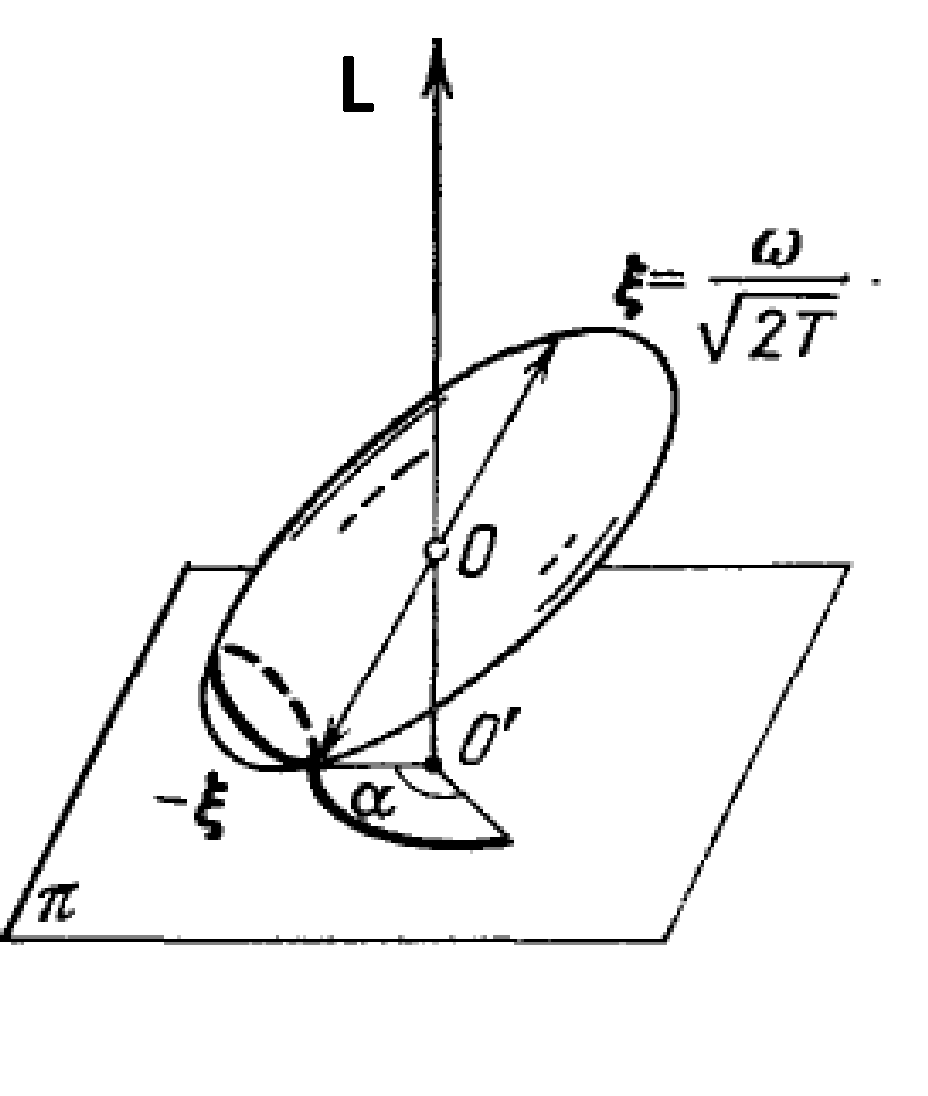


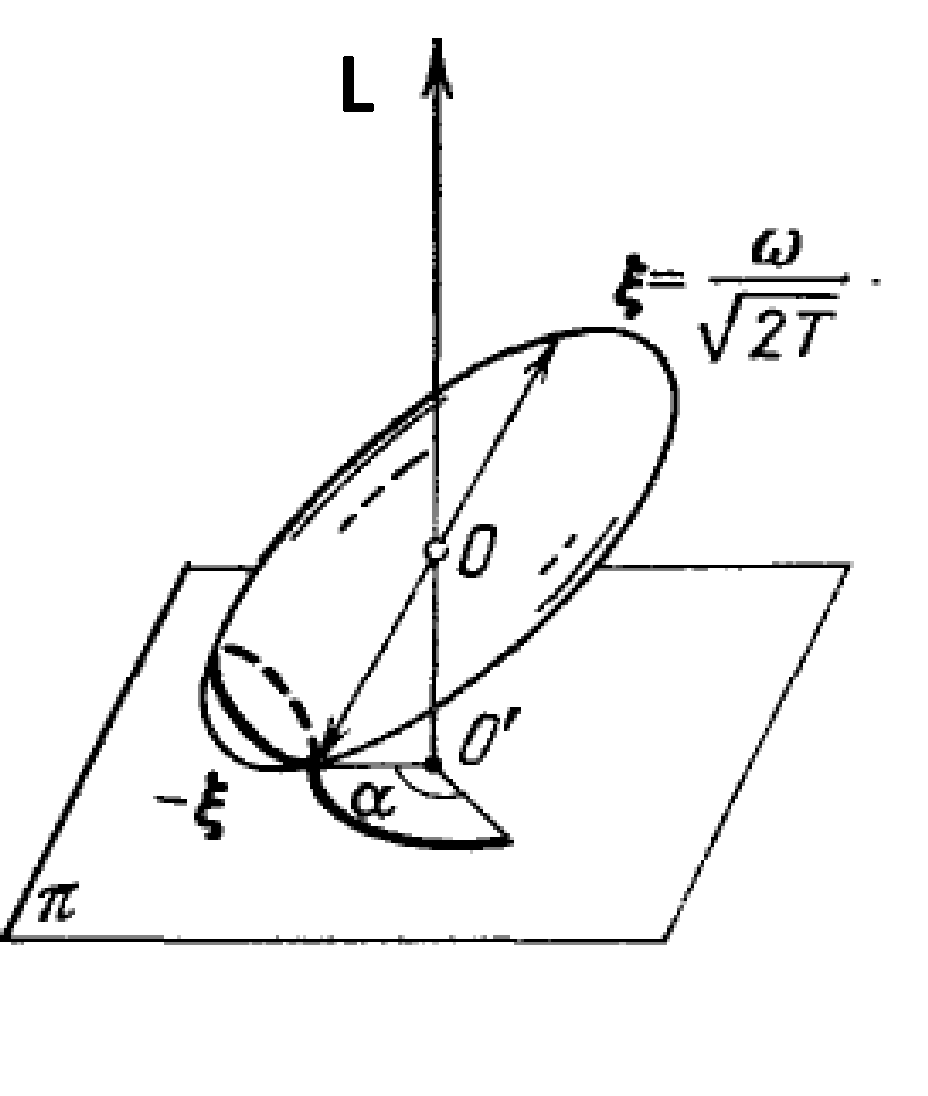

[Back to the course contents](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)